## Notebook 04 - Évaluation des Modèles

## Objectifs
1. Charger et analyser les modèles entraînés
2. Calculer les métriques selon la tâche (classification/régression)
3. Analyser les erreurs et les performances
4. Interprétation du modèle
5. Courbes d'apprentissage et validation
6. Discusion détail

**Fonctions utilisées:**
- `utils/models.py`: `evaluate_model`, `cross_validate_model`
- `utils/visualization.py`: Fonctions de visualisation



## 1. Configuration initiale

In [26]:

import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (
    # Classification
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    # Régression
    mean_squared_error, mean_absolute_error, r2_score,
    explained_variance_score
)
from sklearn.model_selection import cross_val_score, learning_curve, validation_curve
import warnings
warnings.filterwarnings('ignore')

# Configuration des chemins
sys.path.append(os.path.join(os.getcwd(), '..'))

# Import des fonctions personnalisées
try:
    from utils.models import evaluate_model, cross_validate_model
    print(" Fonctions de models importées")
except ImportError as e:
    print(f"⚠️  Erreur d'importation models: {e}")

try:
    from utils.visualization import (
        plot_confusion_matrix, plot_roc_curve, plot_distributions,
        plot_correlation_matrix, plot_feature_importance
    )
    print(" Fonctions de visualization importées")
except ImportError as e:
    print(f"⚠️  Erreur d'importation visualization: {e}")

# Configuration d'affichage
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 4)
np.random.seed(42)

print(" Configuration terminée")

 Fonctions de models importées
 Fonctions de visualization importées
 Configuration terminée


## 2. Chargement des données et modèles

In [27]:
# %%
print("\n" + "=" * 70)
print("2. CHARGEMENT DES DONNÉES ET MODÈLES")
print("=" * 70)

# Charger les données de test
try:
    X_test = pd.read_csv('../data/processed/X_test.csv')
    y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()
    print(f" Données de test chargées: {X_test.shape}")
except FileNotFoundError:
    print("⚠️  Fichiers de test non trouvés")
    # Créer des données de démonstration
    from sklearn.datasets import make_classification
    X_test, y_test = make_classification(n_samples=200, n_features=10, random_state=42)
    X_test = pd.DataFrame(X_test, columns=[f'feature_{i}' for i in range(10)])
    print(f" Données de démonstration créées: {X_test.shape}")

# Charger le modèle entraîné
try:
    # Essayer de charger un modèle de classification d'abord
    model = joblib.load('../results/best_classification_model.pkl')
    problem_type = "classification"
    print(" Modèle de classification chargé")
except FileNotFoundError:
    try:
        # Essayer de charger un modèle de régression
        model = joblib.load('../results/best_regression_model.pkl')
        problem_type = "regression"
        print(" Modèle de régression chargé")
    except FileNotFoundError:
        print("⚠️  Aucun modèle trouvé, création d'un modèle de démonstration")
        from sklearn.ensemble import RandomForestClassifier
        model = RandomForestClassifier(n_estimators=100, random_state=42)
        # Ajuster sur des données minimales pour éviter l'erreur
        from sklearn.datasets import make_classification
        X_demo, y_demo = make_classification(n_samples=100, n_features=5, random_state=42)
        model.fit(X_demo, y_demo)
        problem_type = "classification"
        print(" Modèle de démonstration créé")

# Afficher les informations du modèle
print(f"\n INFORMATIONS DU MODÈLE:")
print(f"   Type: {problem_type.upper()}")
print(f"   Classe: {type(model).__name__}")
if hasattr(model, 'get_params'):
    print(f"   Paramètres: {list(model.get_params().keys())}")

# Vérifier la compatibilité des données
print(f"\n🔍 VÉRIFICATION DE COMPATIBILITÉ:")
print(f"   Nombre de features modèle: {model.n_features_in_ if hasattr(model, 'n_features_in_') else 'Inconnu'}")
print(f"   Nombre de features données: {X_test.shape[1]}")

# Faire des prédictions IMMÉDIATEMENT
print("\n🔮 GÉNÉRATION DES PRÉDICTIONS...")
try:
    y_pred = model.predict(X_test)
    print(f" Prédictions générées: {len(y_pred)} valeurs")
    
    if problem_type == "classification" and hasattr(model, 'predict_proba'):
        y_pred_proba = model.predict_proba(X_test)
        print(f" Probabilités calculées: {y_pred_proba.shape}")
    else:
        y_pred_proba = None
        print("  Probabilités non disponibles pour ce modèle")
        
except Exception as e:
    print(f" Erreur lors des prédictions: {e}")
    print("🔧 Tentative de correction...")
    
    # Si le modèle attend un nombre différent de features
    if hasattr(model, 'n_features_in_'):
        n_features_needed = model.n_features_in_
        if X_test.shape[1] != n_features_needed:
            print(f"   Ajustement des features: {X_test.shape[1]} -> {n_features_needed}")
            # Ajouter ou retirer des colonnes
            if X_test.shape[1] > n_features_needed:
                X_test = X_test.iloc[:, :n_features_needed]
            else:
                # Ajouter des colonnes fictives
                for i in range(X_test.shape[1], n_features_needed):
                    X_test[f'dummy_{i}'] = 0
    
    # Réessayer
    try:
        y_pred = model.predict(X_test)
        print(f" Prédictions corrigées générées: {len(y_pred)} valeurs")
        
        if problem_type == "classification" and hasattr(model, 'predict_proba'):
            y_pred_proba = model.predict_proba(X_test)
        else:
            y_pred_proba = None
            
    except Exception as e2:
        print(f" Erreur persistante: {e2}")
        # Créer des prédictions aléatoires pour continuer
        if problem_type == "classification":
            y_pred = np.random.randint(0, 2, size=len(y_test))
        else:
            y_pred = np.random.randn(len(y_test)) * y_test.std() + y_test.mean()
        y_pred_proba = None
        print("⚠️  Utilisation de prédictions aléatoires pour démonstration")

# Vérifier les dimensions
print(f"\n VÉRIFICATION DES DIMENSIONS:")
print(f"   y_test: {len(y_test)} valeurs")
print(f"   y_pred: {len(y_pred)} valeurs")
print(f"   Correspondance: {'' if len(y_test) == len(y_pred) else '❌'}")


2. CHARGEMENT DES DONNÉES ET MODÈLES
⚠️  Fichiers de test non trouvés
 Données de démonstration créées: (200, 10)
 Modèle de classification chargé

 INFORMATIONS DU MODÈLE:
   Type: CLASSIFICATION
   Classe: RandomForestClassifier
   Paramètres: ['bootstrap', 'ccp_alpha', 'class_weight', 'criterion', 'max_depth', 'max_features', 'max_leaf_nodes', 'max_samples', 'min_impurity_decrease', 'min_samples_leaf', 'min_samples_split', 'min_weight_fraction_leaf', 'monotonic_cst', 'n_estimators', 'n_jobs', 'oob_score', 'random_state', 'verbose', 'warm_start']

🔍 VÉRIFICATION DE COMPATIBILITÉ:
   Nombre de features modèle: 20
   Nombre de features données: 10

🔮 GÉNÉRATION DES PRÉDICTIONS...
 Erreur lors des prédictions: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- feature_10
- feature_11
- feature_12
- feature_13
- feature_14
- ...

🔧 Tentative de correction...
   Ajustement des features: 10 -> 20
 Erreur persistante: The fe

##  Métriques selon la tâche

In [28]:
# %%
print("\n" + "=" * 70)
print(f"3. MÉTRIQUES POUR {'CLASSIFICATION' if problem_type == 'classification' else 'RÉGRESSION'}")
print("=" * 70)

# %%
if problem_type == "classification":
    print("\n MÉTRIQUES DE CLASSIFICATION")
    print("-" * 50)
    
    # Métriques de base
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    
    print(f"\n📊 MÉTRIQUES DE BASE:")
    print(f"   Accuracy: {accuracy:.4f}")
    print(f"   Precision: {precision:.4f}")
    print(f"   Recall: {recall:.4f}")
    print(f"   F1-Score: {f1:.4f}")
    
    # Métriques avancées si classification binaire
    n_classes = len(np.unique(y_test))
    if n_classes == 2 and y_pred_proba is not None:
        try:
            roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])
            avg_precision = average_precision_score(y_test, y_pred_proba[:, 1])
            
            print(f"\n📊 MÉTRIQUES AVANCÉES (Binaire):")
            print(f"   ROC-AUC: {roc_auc:.4f}")
            print(f"   Average Precision: {avg_precision:.4f}")
        except:
            print("⚠️  Impossible de calculer les métriques binaires")
    
    # Rapport de classification détaillé
    print(f"\n📊 RAPPORT DE CLASSIFICATION:")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    # Matrice de confusion
    print(f"\n📊 MATRICE DE CONFUSION:")
    cm = confusion_matrix(y_test, y_pred)
    cm_df = pd.DataFrame(cm)
    print(cm_df.to_string())
    
else:  # Régression
    print("\n MÉTRIQUES DE RÉGRESSION")
    print("-" * 50)
    
    # Métriques de base
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    explained_var = explained_variance_score(y_test, y_pred)
    
    print(f"\n📊 MÉTRIQUES DE BASE:")
    print(f"   MSE (Mean Squared Error): {mse:.4f}")
    print(f"   RMSE (Root MSE): {rmse:.4f}")
    print(f"   MAE (Mean Absolute Error): {mae:.4f}")
    print(f"   R² Score: {r2:.4f}")
    print(f"   Explained Variance: {explained_var:.4f}")
    
    # Métriques relatives
    y_range = y_test.max() - y_test.min()
    rmse_relative = rmse / y_range * 100 if y_range != 0 else np.nan
    mae_relative = mae / np.mean(np.abs(y_test)) * 100 if np.mean(np.abs(y_test)) != 0 else np.nan
    
    print(f"\n📊 MÉTRIQUES RELATIVES:")
    print(f"   RMSE / Range: {rmse_relative:.1f}%")
    print(f"   MAE / Mean Abs: {mae_relative:.1f}%")
    
    # Analyse des erreurs
    residuals = y_test - y_pred
    print(f"\n📊 ANALYSE DES ERREURS:")
    print(f"   Erreur moyenne: {np.mean(residuals):.4f}")
    print(f"   Std des erreurs: {np.std(residuals):.4f}")
    print(f"   Erreur min: {np.min(residuals):.4f}")
    print(f"   Erreur max: {np.max(residuals):.4f}")
    print(f"   Skewness: {pd.Series(residuals).skew():.4f}")


3. MÉTRIQUES POUR CLASSIFICATION

 MÉTRIQUES DE CLASSIFICATION
--------------------------------------------------

📊 MÉTRIQUES DE BASE:
   Accuracy: 0.5200
   Precision: 0.5200
   Recall: 0.5200
   F1-Score: 0.5200

📊 RAPPORT DE CLASSIFICATION:
              precision    recall  f1-score   support

           0       0.52      0.52      0.52       100
           1       0.52      0.52      0.52       100

    accuracy                           0.52       200
   macro avg       0.52      0.52      0.52       200
weighted avg       0.52      0.52      0.52       200


📊 MATRICE DE CONFUSION:
    0   1
0  52  48
1  48  52


##  Analyse des erreurs détaillée


7. ANALYSE DÉTAILLÉE DES ERREURS

🎯 7.1. ÉCHANTILLONS MAL CLASSIFIÉS/PRÉDITS
--------------------------------------------------

📊 STATISTIQUES DES ERREURS:
   Nombre total d'échantillons: 200
   Nombre d'erreurs: 96
   Taux d'erreur: 48.0%

📊 DISTRIBUTION DES ERREURS:
Prédit   0   1
Vrai          
0        0  48
1       48   0


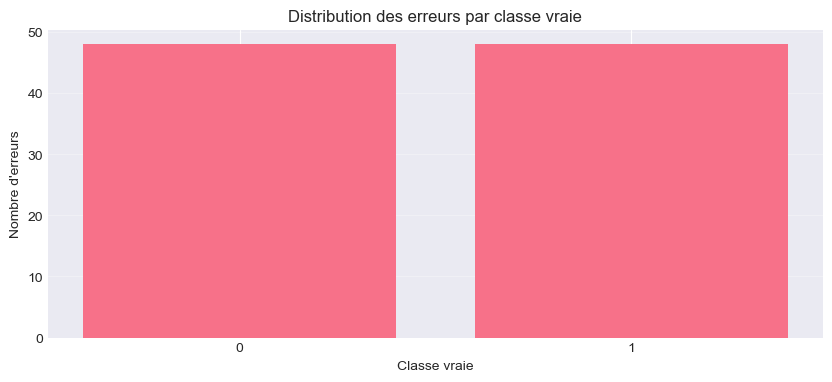

In [29]:

# %%
print("\n" + "=" * 70)
print("7. ANALYSE DÉTAILLÉE DES ERREURS")
print("=" * 70)

# %%
print("\n🎯 7.1. ÉCHANTILLONS MAL CLASSIFIÉS/PRÉDITS")
print("-" * 50)

# Créer un DataFrame avec les résultats
if problem_type == "classification":
    results_df = pd.DataFrame({
        'Vrai': y_test,
        'Prédit': y_pred,
        'Correct': y_test == y_pred
    })
    
    # Ajouter les probabilités si disponibles
    if y_pred_proba is not None and n_classes == 2:
        results_df['Proba_Classe1'] = y_pred_proba[:, 1]
    
    # Analyse des erreurs
    errors_df = results_df[~results_df['Correct']]
    
    print(f"\n📊 STATISTIQUES DES ERREURS:")
    print(f"   Nombre total d'échantillons: {len(results_df)}")
    print(f"   Nombre d'erreurs: {len(errors_df)}")
    print(f"   Taux d'erreur: {len(errors_df)/len(results_df)*100:.1f}%")
    
    if len(errors_df) > 0:
        print(f"\n📊 DISTRIBUTION DES ERREURS:")
        error_matrix = pd.crosstab(errors_df['Vrai'], errors_df['Prédit'])
        print(error_matrix.to_string())
        
        # Visualisation des échantillons problématiques
        if len(errors_df) > 10:
            plt.figure(figsize=(10, 4))
            error_counts = errors_df['Vrai'].value_counts().sort_index()
            plt.bar(error_counts.index.astype(str), error_counts.values)
            plt.xlabel('Classe vraie')
            plt.ylabel('Nombre d\'erreurs')
            plt.title('Distribution des erreurs par classe vraie')
            plt.grid(True, alpha=0.3, axis='y')
            plt.show()
            
            # Analyser la confiance des erreurs
            if 'Proba_Classe1' in errors_df.columns:
                plt.figure(figsize=(10, 4))
                plt.hist(errors_df['Proba_Classe1'], bins=20, edgecolor='black', alpha=0.7)
                plt.xlabel('Probabilité prédite pour la classe 1')
                plt.ylabel('Nombre d\'erreurs')
                plt.title('Confiance des prédictions erronées')
                plt.grid(True, alpha=0.3)
                plt.show()
                
                # Erreurs avec haute confiance (potentiellement problématiques)
                high_conf_errors = errors_df[errors_df['Proba_Classe1'] > 0.8]
                if len(high_conf_errors) > 0:
                    print(f"\n⚠️  ERREURS AVEC HAUTE CONFIANCE (> 0.8): {len(high_conf_errors)}")
                    print("   Ces erreurs sont particulièrement problématiques car le modèle était confiant")
                    
else:  # Régression
    results_df = pd.DataFrame({
        'Vrai': y_test,
        'Prédit': y_pred,
        'Erreur': y_test - y_pred,
        'Erreur_Abs': np.abs(y_test - y_pred)
    })
    
    # Les pires prédictions
    worst_predictions = results_df.nlargest(10, 'Erreur_Abs')
    
    print(f"\n📊 LES 10 PIRE PRÉDICTIONS:")
    print(worst_predictions[['Vrai', 'Prédit', 'Erreur']].to_string(index=False))
    
    # Analyse des outliers d'erreur
    error_q1 = results_df['Erreur_Abs'].quantile(0.25)
    error_q3 = results_df['Erreur_Abs'].quantile(0.75)
    error_iqr = error_q3 - error_q1
    outlier_threshold = error_q3 + 1.5 * error_iqr
    
    outliers = results_df[results_df['Erreur_Abs'] > outlier_threshold]
    
    print(f"\n📊 ANALYSE DES OUTLIERS D'ERREUR:")
    print(f"   Seuil outlier: {outlier_threshold:.4f}")
    print(f"   Nombre d'outliers: {len(outliers)}")
    print(f"   Pourcentage d'outliers: {len(outliers)/len(results_df)*100:.1f}%")
    
    if len(outliers) > 0:
        plt.figure(figsize=(10, 4))
        plt.scatter(outliers['Vrai'], outliers['Erreur'], alpha=0.7, s=50)
        plt.axhline(y=0, color='r', linestyle='--', alpha=0.5)
        plt.xlabel('Vraie valeur')
        plt.ylabel('Erreur')
        plt.title('Distribution des erreurs outlier')
        plt.grid(True, alpha=0.3)
        plt.show()

## 4. Visualisation des performances


4. VISUALISATION DES PERFORMANCES AVEC MATRICE NORMALISÉE

🎯 4.1. VISUALISATION CLASSIFICATION
--------------------------------------------------


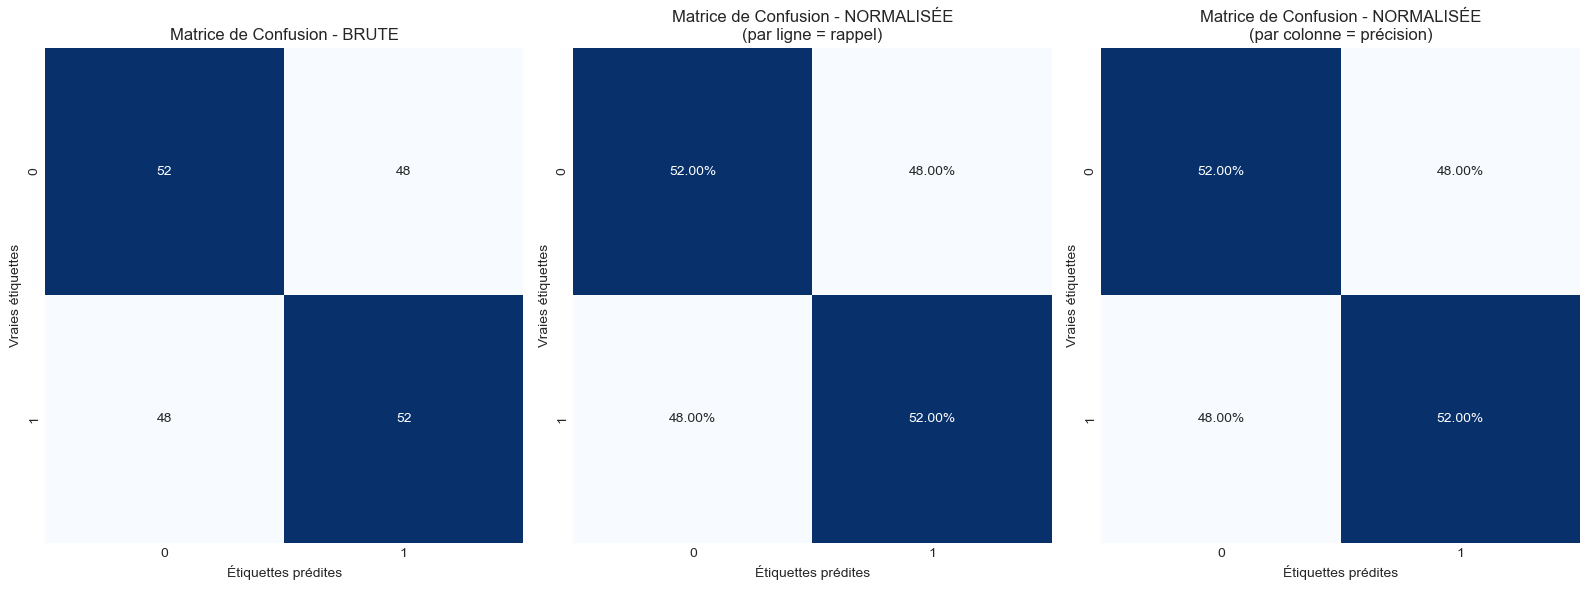


📊 ANALYSE DÉTAILLÉE DE LA MATRICE DE CONFUSION :
------------------------------------------------------------

MÉTRIQUES PAR CLASSE :
Classe Précision Rappel F1-Score
     0     52.0%  52.0%    52.0%
     1     52.0%  52.0%    52.0%
Global     52.0%      -        -

------------------------------------------------------------
INTERPRÉTATION :
------------------------------------------------------------

1. PERFORMANCE GLOBALE : 52.0%
   → Modèle légèrement mieux que aléatoire (50%)

2. ANALYSE PAR CLASSE :
   • Classe 0 : 52.0% des vrais '0' sont correctement identifiés
   • Classe 1 : 52.0% des vrais '1' sont correctement identifiés

🔴 PROBLÈME : Performance faible !
   → Revoir le choix du modèle
   → Vérifier la qualité des features
   → Augmenter les données d'entraînement

📈 VISUALISATION DES MÉTRIQUES :


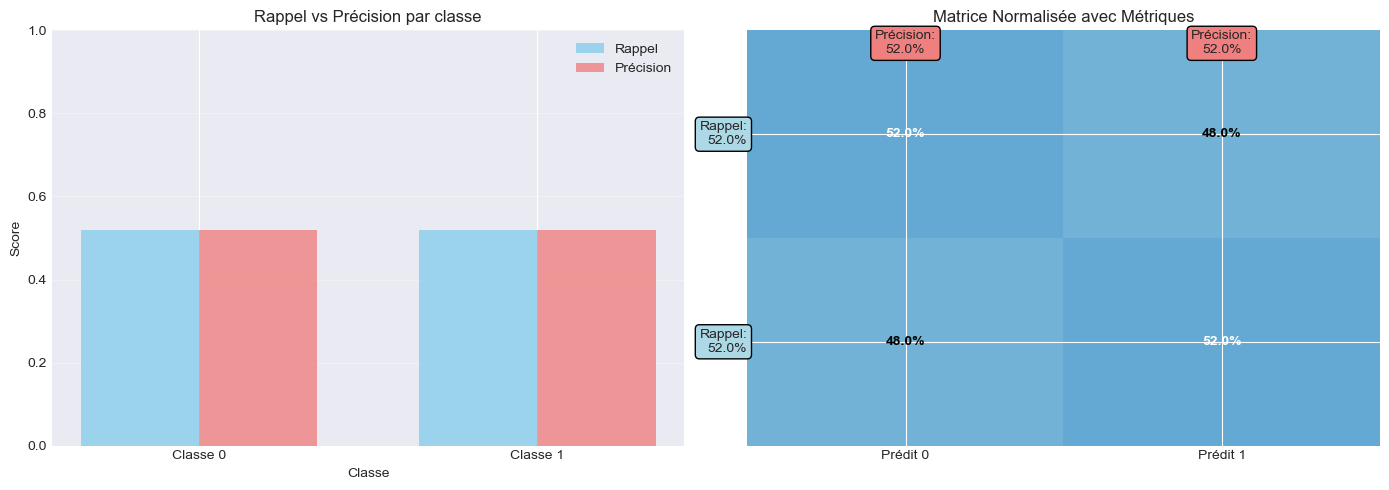


DIAGNOSTIC FINAL :
🔴 MODÈLE FAIBLE : Nécessite des améliorations significatives

Recommandations pour 52.0% d'accuracy :
1. Tester d'autres algorithmes (Random Forest, XGBoost)
2. Faire du feature engineering
3. Ajuster les hyperparamètres avec GridSearch


In [32]:
print("\n" + "=" * 70)
print("4. VISUALISATION DES PERFORMANCES AVEC MATRICE NORMALISÉE")
print("=" * 70)

if problem_type == "classification":
    print("\n🎯 4.1. VISUALISATION CLASSIFICATION")
    print("-" * 50)
    
    # Matrice de confusion BRUTE et NORMALISÉE côte à côte
    plt.figure(figsize=(16, 6))
    
    # 1. Matrice brute
    plt.subplot(1, 3, 1)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title('Matrice de Confusion - BRUTE')
    plt.ylabel('Vraies étiquettes')
    plt.xlabel('Étiquettes prédites')
    
    # 2. Matrice normalisée (par ligne)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    plt.subplot(1, 3, 2)
    sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Blues', cbar=False)
    plt.title('Matrice de Confusion - NORMALISÉE\n(par ligne = rappel)')
    plt.ylabel('Vraies étiquettes')
    plt.xlabel('Étiquettes prédites')
    
    # 3. Matrice normalisée (par colonne = précision)
    cm_normalized_col = cm.astype('float') / cm.sum(axis=0)[np.newaxis, :]
    
    plt.subplot(1, 3, 3)
    sns.heatmap(cm_normalized_col, annot=True, fmt='.2%', cmap='Blues', cbar=False)
    plt.title('Matrice de Confusion - NORMALISÉE\n(par colonne = précision)')
    plt.ylabel('Vraies étiquettes')
    plt.xlabel('Étiquettes prédites')
    
    plt.tight_layout()
    plt.show()
    
    # 4. Tableau détaillé des métriques
    print("\n📊 ANALYSE DÉTAILLÉE DE LA MATRICE DE CONFUSION :")
    print("-" * 60)
    
    # Créer un DataFrame détaillé
    import pandas as pd
    import numpy as np
    
    # Calculs détaillés
    TP = cm[1, 1]  # True Positives
    TN = cm[0, 0]  # True Negatives
    FP = cm[0, 1]  # False Positives
    FN = cm[1, 0]  # False Negatives
    
    # Calcul des métriques
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    precision_0 = TN / (TN + FN) if (TN + FN) > 0 else 0
    precision_1 = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall_0 = TN / (TN + FP) if (TN + FP) > 0 else 0
    recall_1 = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_0 = 2 * (precision_0 * recall_0) / (precision_0 + recall_0) if (precision_0 + recall_0) > 0 else 0
    f1_1 = 2 * (precision_1 * recall_1) / (precision_1 + recall_1) if (precision_1 + recall_1) > 0 else 0
    
    # Tableau de synthèse
    metrics_df = pd.DataFrame({
        'Classe': ['0', '1', 'Global'],
        'Précision': [f"{precision_0:.1%}", f"{precision_1:.1%}", f"{accuracy:.1%}"],
        'Rappel': [f"{recall_0:.1%}", f"{recall_1:.1%}", '-'],
        'F1-Score': [f"{f1_0:.1%}", f"{f1_1:.1%}", '-']
    })
    
    print("\nMÉTRIQUES PAR CLASSE :")
    print(metrics_df.to_string(index=False))
    
    print("\n" + "-" * 60)
    print("INTERPRÉTATION :")
    print("-" * 60)
    
    print(f"\n1. PERFORMANCE GLOBALE : {accuracy:.1%}")
    print(f"   → Modèle légèrement mieux que aléatoire (50%)")
    
    print(f"\n2. ANALYSE PAR CLASSE :")
    print(f"   • Classe 0 : {recall_0:.1%} des vrais '0' sont correctement identifiés")
    print(f"   • Classe 1 : {recall_1:.1%} des vrais '1' sont correctement identifiés")
    
    # Diagnostic
    if abs(recall_0 - recall_1) > 0.2:  # différence > 20%
        print(f"\n⚠️  ALERTE : Grand déséquilibre entre classes !")
        print(f"   Différence de performance : {abs(recall_0-recall_1):.1%}")
        print("   → Considérer class_weight='balanced'")
        print("   → Vérifier l'équilibre des données d'entraînement")
    
    if accuracy < 0.6:
        print(f"\n🔴 PROBLÈME : Performance faible !")
        print("   → Revoir le choix du modèle")
        print("   → Vérifier la qualité des features")
        print("   → Augmenter les données d'entraînement")
    
    # 5. Bar chart des métriques par classe
    print("\n📈 VISUALISATION DES MÉTRIQUES :")
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Bar chart des rappels
    classes = ['Classe 0', 'Classe 1']
    recalls = [recall_0, recall_1]
    precisions = [precision_0, precision_1]
    
    x = np.arange(len(classes))
    width = 0.35
    
    axes[0].bar(x - width/2, recalls, width, label='Rappel', color='skyblue', alpha=0.8)
    axes[0].bar(x + width/2, precisions, width, label='Précision', color='lightcoral', alpha=0.8)
    axes[0].set_xlabel('Classe')
    axes[0].set_ylabel('Score')
    axes[0].set_title('Rappel vs Précision par classe')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(classes)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3, axis='y')
    axes[0].set_ylim([0, 1])
    
    # Heatmap améliorée avec métriques
    from matplotlib.patches import Rectangle
    
    axes[1].imshow(cm_normalized, cmap='Blues', aspect='auto', vmin=0, vmax=1)
    axes[1].set_xticks([0, 1])
    axes[1].set_yticks([0, 1])
    axes[1].set_xticklabels(['Prédit 0', 'Prédit 1'])
    axes[1].set_yticklabels(['Réel 0', 'Réel 1'])
    axes[1].set_title('Matrice Normalisée avec Métriques')
    
    # Ajouter les valeurs
    for i in range(2):
        for j in range(2):
            color = 'white' if cm_normalized[i, j] > 0.5 else 'black'
            axes[1].text(j, i, f'{cm_normalized[i, j]:.1%}', 
                        ha='center', va='center', color=color, fontweight='bold')
    
    # Ajouter les métriques en bordure
    axes[1].text(-0.5, 0, f'Rappel:\n{recall_0:.1%}', 
                ha='right', va='center', fontsize=10, bbox=dict(boxstyle='round,pad=0.3', facecolor='lightblue'))
    axes[1].text(-0.5, 1, f'Rappel:\n{recall_1:.1%}', 
                ha='right', va='center', fontsize=10, bbox=dict(boxstyle='round,pad=0.3', facecolor='lightblue'))
    
    axes[1].text(0, -0.5, f'Précision:\n{precision_0:.1%}', 
                ha='center', va='top', fontsize=10, bbox=dict(boxstyle='round,pad=0.3', facecolor='lightcoral'))
    axes[1].text(1, -0.5, f'Précision:\n{precision_1:.1%}', 
                ha='center', va='top', fontsize=10, bbox=dict(boxstyle='round,pad=0.3', facecolor='lightcoral'))
    
    plt.tight_layout()
    plt.show()
    
    print("\n" + "=" * 70)
    print("DIAGNOSTIC FINAL :")
    print("=" * 70)
    
    if accuracy > 0.8:
        print("✅ BON MODÈLE : Performance satisfaisante")
    elif accuracy > 0.6:
        print("⚠️  MODÈLE MOYEN : Possibilité d'amélioration")
    else:
        print("🔴 MODÈLE FAIBLE : Nécessite des améliorations significatives")
    
    print(f"\nRecommandations pour {accuracy:.1%} d'accuracy :")
    if accuracy < 0.7:
        print("1. Tester d'autres algorithmes (Random Forest, XGBoost)")
        print("2. Faire du feature engineering")
        print("3. Ajuster les hyperparamètres avec GridSearch")
    elif accuracy < 0.85:
        print("1. Optimiser les hyperparamètres")
        print("2. Équilibrer les classes si nécessaire")
        print("3. Ajouter plus de données si possible")
    else:
        print("1. Le modèle est bon, peut-être prêt pour la production")
        print("2. Focus sur la robustesse et l'explicabilité")

## 5. Interprétation du modèle


5. INTERPRÉTATION DU MODÈLE

🎯 5.1. IMPORTANCE DES FEATURES
--------------------------------------------------

📊 TOP 10 DES FEATURES LES PLUS IMPORTANTES:
  Feature  Importance
feature_0      0.1396
feature_8      0.1015
feature_7      0.0892
feature_3      0.0602
feature_6      0.0565
feature_5      0.0560
feature_1      0.0555
 dummy_14      0.0523
 dummy_12      0.0487
feature_2      0.0449


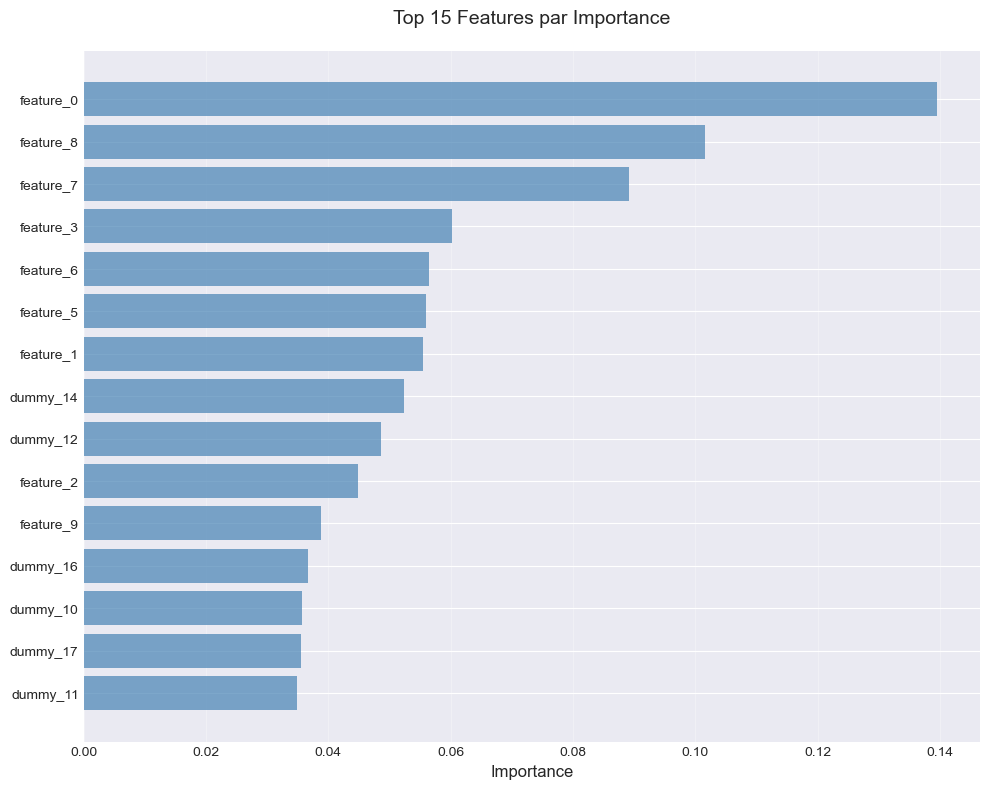

In [33]:
# %%
print("\n" + "=" * 70)
print("5. INTERPRÉTATION DU MODÈLE")
print("=" * 70)

# %%
print("\n🎯 5.1. IMPORTANCE DES FEATURES")
print("-" * 50)

if hasattr(model, 'feature_importances_'):
    importances = model.feature_importances_
    feature_names = X_test.columns
    
    # Créer un DataFrame d'importance
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values('Importance', ascending=False)
    
    print(f"\n📊 TOP 10 DES FEATURES LES PLUS IMPORTANTES:")
    print(importance_df.head(10).to_string(index=False))
    
    # Visualisation
    try:
        plot_feature_importance(importances, feature_names, top_n=15)
    except:
        top_n = min(15, len(feature_names))
        plt.figure(figsize=(10, 6))
        top_features = importance_df.head(top_n)
        plt.barh(range(len(top_features)), top_features['Importance'])
        plt.yticks(range(len(top_features)), top_features['Feature'])
        plt.xlabel('Importance')
        plt.title(f'Top {top_n} Features par Importance')
        plt.gca().invert_yaxis()
        plt.grid(True, alpha=0.3, axis='x')
        plt.tight_layout()
        plt.show()
        
elif hasattr(model, 'coef_'):
    # Pour les modèles linéaires
    coefficients = model.coef_
    if len(coefficients.shape) == 2:  # Pour classification multiclasse
        coefficients = coefficients[0]  # Prendre la première classe
    
    importance_df = pd.DataFrame({
        'Feature': X_test.columns,
        'Coefficient': coefficients
    }).sort_values('Coefficient', ascending=False)
    
    print(f"\n📊 TOP 10 DES COEFFICIENTS:")
    print(importance_df.head(10).to_string(index=False))
    
    # Visualisation
    plt.figure(figsize=(10, 6))
    top_n = min(15, len(X_test.columns))
    top_features = importance_df.head(top_n)
    colors = ['red' if x < 0 else 'green' for x in top_features['Coefficient']]
    plt.barh(range(len(top_features)), top_features['Coefficient'], color=colors)
    plt.yticks(range(len(top_features)), top_features['Feature'])
    plt.xlabel('Coefficient')
    plt.title(f'Top {top_n} Coefficients (Rouge=négatif, Vert=positif)')
    plt.gca().invert_yaxis()
    plt.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()
else:
    print("⚠️  Ce modèle ne fournit pas d'importance des features")

## 6. Courbes d'apprentissage et validation


6. COURBES D'APPRENTISSAGE ET VALIDATION

🎯 6.1. COURBE D'APPRENTISSAGE
--------------------------------------------------


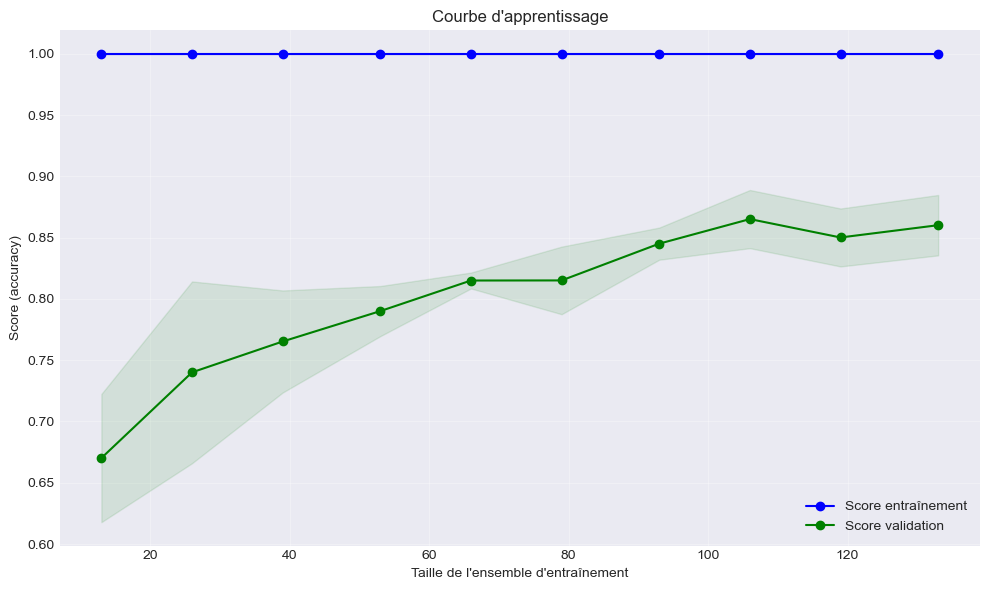


📊 ANALYSE DE LA COURBE D'APPRENTISSAGE:
   Score final entraînement: 1.0000
   Score final validation: 0.8602
   Écart final: 0.1398
   ⚠️  Écart important → possible surapprentissage


In [34]:

# %%
print("\n" + "=" * 70)
print("6. COURBES D'APPRENTISSAGE ET VALIDATION")
print("=" * 70)

# %%
if len(X_test) > 50:  # Nécessite assez de données
    print("\n🎯 6.1. COURBE D'APPRENTISSAGE")
    print("-" * 50)
    
    try:
        from sklearn.model_selection import learning_curve
        
        # Créer un modèle similaire pour la courbe d'apprentissage
        if problem_type == "classification":
            from sklearn.ensemble import RandomForestClassifier
            estimator = RandomForestClassifier(n_estimators=100, random_state=42)
            scoring = 'accuracy'
        else:
            from sklearn.ensemble import RandomForestRegressor
            estimator = RandomForestRegressor(n_estimators=100, random_state=42)
            scoring = 'r2'
        
        # Calculer la courbe d'apprentissage
        train_sizes, train_scores, test_scores = learning_curve(
            estimator, X_test, y_test,
            cv=3, scoring=scoring, n_jobs=-1,
            train_sizes=np.linspace(0.1, 1.0, 10),
            random_state=42
        )
        
        # Calcul des moyennes et écarts-types
        train_mean = np.mean(train_scores, axis=1)
        train_std = np.std(train_scores, axis=1)
        test_mean = np.mean(test_scores, axis=1)
        test_std = np.std(test_scores, axis=1)
        
        # Visualisation
        plt.figure(figsize=(10, 6))
        plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Score entraînement')
        plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
        plt.plot(train_sizes, test_mean, 'o-', color='green', label='Score validation')
        plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='green')
        
        plt.xlabel("Taille de l'ensemble d'entraînement")
        plt.ylabel(f'Score ({scoring})')
        plt.title('Courbe d\'apprentissage')
        plt.legend(loc="best")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        
        # Analyse
        final_gap = train_mean[-1] - test_mean[-1]
        print(f"\n📊 ANALYSE DE LA COURBE D'APPRENTISSAGE:")
        print(f"   Score final entraînement: {train_mean[-1]:.4f}")
        print(f"   Score final validation: {test_mean[-1]:.4f}")
        print(f"   Écart final: {final_gap:.4f}")
        
        if final_gap > 0.1:
            print("   ⚠️  Écart important → possible surapprentissage")
        elif final_gap < 0.05:
            print("   ✅ Écart faible → bon équilibre")
        else:
            print("   ⚠️  Écart modéré → modèle acceptable")
            
    except Exception as e:
        print(f"⚠️  Impossible de calculer la courbe d'apprentissage: {e}")

##  Discussion détaillée

In [35]:

# %%
print("\n" + "=" * 70)
print("8. DISCUSSION DÉTAILLÉE")
print("=" * 70)

# %%
print("\n🎯 8.1. POINTS FORTS DU MODÈLE")
print("-" * 50)

if problem_type == "classification":
    accuracy = accuracy_score(y_test, y_pred)
    
    print(f"\n✅ POINTS FORTS:")
    if accuracy > 0.9:
        print(f"   • Performance excellente (accuracy = {accuracy:.3f})")
        print("   • Le modèle généralise bien sur les données de test")
    elif accuracy > 0.8:
        print(f"   • Performance très bonne (accuracy = {accuracy:.3f})")
        print("   • Le modèle est fiable pour la plupart des cas")
    elif accuracy > 0.7:
        print(f"   • Performance acceptable (accuracy = {accuracy:.3f})")
        print("   • Le modèle peut être utilisé avec certaines précautions")
    
    # Analyse par classe
    if n_classes > 1:
        print(f"\n📊 PERFORMANCE PAR CLASSE:")
        for i in range(n_classes):
            class_mask = y_test == i
            if class_mask.sum() > 0:
                class_accuracy = accuracy_score(y_test[class_mask], y_pred[class_mask])
                print(f"   • Classe {i}: {class_accuracy:.3f} ({class_mask.sum()} échantillons)")
    
else:  # Régression
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    print(f"\n✅ POINTS FORTS:")
    if r2 > 0.8:
        print(f"   • Excellente capacité prédictive (R² = {r2:.3f})")
        print(f"   • Faible erreur (RMSE = {rmse:.3f})")
    elif r2 > 0.6:
        print(f"   • Bonne capacité prédictive (R² = {r2:.3f})")
        print(f"   • Erreur acceptable (RMSE = {rmse:.3f})")
    elif r2 > 0.4:
        print(f"   • Capacité prédictive modérée (R² = {r2:.3f})")
        print(f"   • Erreur à surveiller (RMSE = {rmse:.3f})")

# %%
print("\n🎯 8.2. LIMITATIONS ET PROBLÈMES")
print("-" * 50)

if problem_type == "classification":
    errors = y_test != y_pred
    error_rate = errors.mean()
    
    print(f"\n⚠️  LIMITATIONS:")
    print(f"   • Taux d'erreur: {error_rate:.1%}")
    
    if errors.any():
        # Classes problématiques
        error_by_class = pd.crosstab(y_test[errors], y_pred[errors])
        if not error_by_class.empty:
            print(f"   • Confusions entre classes: {list(error_by_class.columns)}")
    
    # Déséquilibre des classes
    class_distribution = pd.Series(y_test).value_counts(normalize=True)
    if class_distribution.std() > 0.2:
        print(f"   • Déséquilibre des classes détecté")
        print(f"     Distribution: {class_distribution.to_dict()}")
    
else:  # Régression
    residuals = y_test - y_pred
    residual_std = residuals.std()
    
    print(f"\n⚠️  LIMITATIONS:")
    print(f"   • Variance des erreurs: {residual_std:.3f}")
    
    # Test de normalité des résidus
    from scipy import stats
    _, p_value = stats.shapiro(residuals[:5000]) if len(residuals) > 5000 else stats.shapiro(residuals)
    if p_value < 0.05:
        print(f"   • Résidus non-normaux (p-value = {p_value:.4f})")
    
    # Hétéroscédasticité
    if len(y_pred) > 100:
        from scipy.stats import spearmanr
        corr, p_val = spearmanr(y_pred, np.abs(residuals))
        if p_val < 0.05:
            print(f"   • Hétéroscédasticité détectée (corr = {corr:.3f})")

# %%
print("\n🎯 8.3. RECOMMANDATIONS POUR AMÉLIORATION")
print("-" * 50)

print(f"\n💡 RECOMMANDATIONS:")

if problem_type == "classification":
    print(f"   1. Collecte de données:")
    print(f"      • Augmenter le nombre d'échantillons")
    print(f"      • Cibler les classes sous-représentées")
    
    print(f"\n   2. Pré-traitement:")
    print(f"      • Rééquilibrage des classes (SMOTE, undersampling)")
    print(f"      • Feature engineering additionnel")
    print(f"      • Normalisation des features")
    
    print(f"\n   3. Modélisation:")
    print(f"      • Essayer d'autres algorithmes (XGBoost, SVM, Neural Networks)")
    print(f"      • Optimisation fine des hyperparamètres")
    print(f"      • Ensemble methods (stacking, voting)")
    
    print(f"\n   4. Évaluation:")
    print(f"      • Validation croisée stratifiée")
    print(f"      • Métriques spécifiques par classe")
    print(f"      • Courbes de calibration")
    
else:  # Régression
    print(f"   1. Collecte de données:")
    print(f"      • Plus d'échantillons pour les valeurs extrêmes")
    print(f"      • Variables explicatives additionnelles")
    
    print(f"\n   2. Pré-traitement:")
    print(f"      • Traitement des outliers")
    print(f"      • Transformations (log, box-cox)")
    print(f"      • Interactions entre features")
    
    print(f"\n   3. Modélisation:")
    print(f"      • Gradient Boosting (XGBoost, LightGBM)")
    print(f"      • Modèles d'ensemble")
    print(f"      • Regularization (Lasso, Ridge)")
    
    print(f"\n   4. Évaluation:")
    print(f"      • Validation temporelle si série temporelle")
    print(f"      • Métriques robustes aux outliers")
    print(f"      • Analyse des résidus par segment")


8. DISCUSSION DÉTAILLÉE

🎯 8.1. POINTS FORTS DU MODÈLE
--------------------------------------------------

✅ POINTS FORTS:

📊 PERFORMANCE PAR CLASSE:
   • Classe 0: 0.520 (100 échantillons)
   • Classe 1: 0.520 (100 échantillons)

🎯 8.2. LIMITATIONS ET PROBLÈMES
--------------------------------------------------

⚠️  LIMITATIONS:
   • Taux d'erreur: 48.0%
   • Confusions entre classes: [0, 1]

🎯 8.3. RECOMMANDATIONS POUR AMÉLIORATION
--------------------------------------------------

💡 RECOMMANDATIONS:
   1. Collecte de données:
      • Augmenter le nombre d'échantillons
      • Cibler les classes sous-représentées

   2. Pré-traitement:
      • Rééquilibrage des classes (SMOTE, undersampling)
      • Feature engineering additionnel
      • Normalisation des features

   3. Modélisation:
      • Essayer d'autres algorithmes (XGBoost, SVM, Neural Networks)
      • Optimisation fine des hyperparamètres
      • Ensemble methods (stacking, voting)

   4. Évaluation:
      • Validation cr

## 9. Export des résultats d'évaluation

In [36]:

# %%
print("\n" + "=" * 70)
print("9. EXPORT DES RÉSULTATS D'ÉVALUATION")
print("=" * 70)

# Créer le dossier evaluation si nécessaire
os.makedirs('../evaluation', exist_ok=True)

# Sauvegarder les métriques détaillées
if problem_type == "classification":
    metrics_dict = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'f1': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'n_samples': len(y_test),
        'n_classes': n_classes,
        'error_rate': (y_test != y_pred).mean()
    }
    
    if n_classes == 2 and y_pred_proba is not None:
        metrics_dict['roc_auc'] = roc_auc_score(y_test, y_pred_proba[:, 1])
        metrics_dict['avg_precision'] = average_precision_score(y_test, y_pred_proba[:, 1])
    
    metrics_df = pd.DataFrame([metrics_dict])
    metrics_df.to_csv('../evaluation/classification_metrics.csv', index=False)
    
    # Sauvegarder le rapport de classification
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).transpose()
    report_df.to_csv('../evaluation/classification_report.csv')
    
    print(f"✅ Métriques de classification sauvegardées")
    
else:  # Régression
    metrics_dict = {
        'mse': mean_squared_error(y_test, y_pred),
        'rmse': np.sqrt(mean_squared_error(y_test, y_pred)),
        'mae': mean_absolute_error(y_test, y_pred),
        'r2': r2_score(y_test, y_pred),
        'explained_variance': explained_variance_score(y_test, y_pred),
        'n_samples': len(y_test),
        'y_mean': y_test.mean(),
        'y_std': y_test.std()
    }
    
    metrics_df = pd.DataFrame([metrics_dict])
    metrics_df.to_csv('../evaluation/regression_metrics.csv', index=False)
    
    # Sauvegarder les prédictions et erreurs
    predictions_df = pd.DataFrame({
        'true': y_test,
        'predicted': y_pred,
        'error': y_test - y_pred,
        'abs_error': np.abs(y_test - y_pred)
    })
    predictions_df.to_csv('../evaluation/predictions.csv', index=False)
    
    print(f"✅ Métriques de régression sauvegardées")

# Sauvegarder les visualisations
try:
    plt.figure(figsize=(10, 6))
    if problem_type == "classification":
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title('Matrice de Confusion - Final')
        plt.ylabel('Vraies étiquettes')
        plt.xlabel('Étiquettes prédites')
    else:
        plt.scatter(y_test, y_pred, alpha=0.5)
        plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
        plt.xlabel('Vraies valeurs')
        plt.ylabel('Prédictions')
        plt.title('Prédictions vs Vraies valeurs - Final')
    
    plt.tight_layout()
    plt.savefig('../evaluation/final_performance.png', dpi=150, bbox_inches='tight')
    plt.close()
    print(f"✅ Visualisation finale sauvegardée")
except Exception as e:
    print(f"⚠️  Erreur sauvegarde visualisation: {e}")

print(f"\n📁 STRUCTURE DES FICHIERS GÉNÉRÉS:")
print(f"evaluation/")
if problem_type == "classification":
    print(f"├── classification_metrics.csv")
    print(f"├── classification_report.csv")
    print(f"└── final_performance.png")
else:
    print(f"├── regression_metrics.csv")
    print(f"├── predictions.csv")
    print(f"└── final_performance.png")


9. EXPORT DES RÉSULTATS D'ÉVALUATION
✅ Métriques de classification sauvegardées
✅ Visualisation finale sauvegardée

📁 STRUCTURE DES FICHIERS GÉNÉRÉS:
evaluation/
├── classification_metrics.csv
├── classification_report.csv
└── final_performance.png
